In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
results = pd.read_csv('TestResults.csv')
results["f1"] = results["f1"].astype(str).str.extract(r"([\d\.]+)").astype(float)

In [3]:
print(results)

      records  epochs  sdti_epochs        f1       acc    memory      data  \
0        2000      59           30  1.000000  1.000000  6.639022  6.615224   
1        2000      59           25  1.000000  1.000000  6.638949  6.615224   
2        2000      59           20  1.000000  1.000000  6.638840  6.615224   
3        2000      59           15  1.000000  1.000000  6.638657  6.615224   
4        2000      59           10  1.000000  1.000000  6.638293  6.615224   
...       ...     ...          ...       ...       ...       ...       ...   
3595      100       1           25  0.696078  0.764706  0.350559  6.615224   
3596      100       1           20  0.598039  0.647059  0.350491  6.615224   
3597      100       1           15  0.627451  0.647059  0.350377  6.615224   
3598      100       1           10  0.588235  0.647059  0.350149  6.615224   
3599      100       1            5  0.519608  0.588235  0.349466  6.615224   

           ttc  
0     4.407809  
1     4.121808  
2     3.8591

In [4]:
max_records = results['records'].max()
max_epochs = results['epochs'].max()
max_sdti_epochs = results['sdti_epochs'].max()

In [5]:
records_abalation = results[(results['epochs']==max_epochs) & (results['sdti_epochs']==max_sdti_epochs)]
epochs_abalation = results[(results['records']==max_records) & (results['sdti_epochs']==max_sdti_epochs)]
sdti_epochs_abalation = results[(results['records']==max_records) & (results['epochs']==max_epochs)]

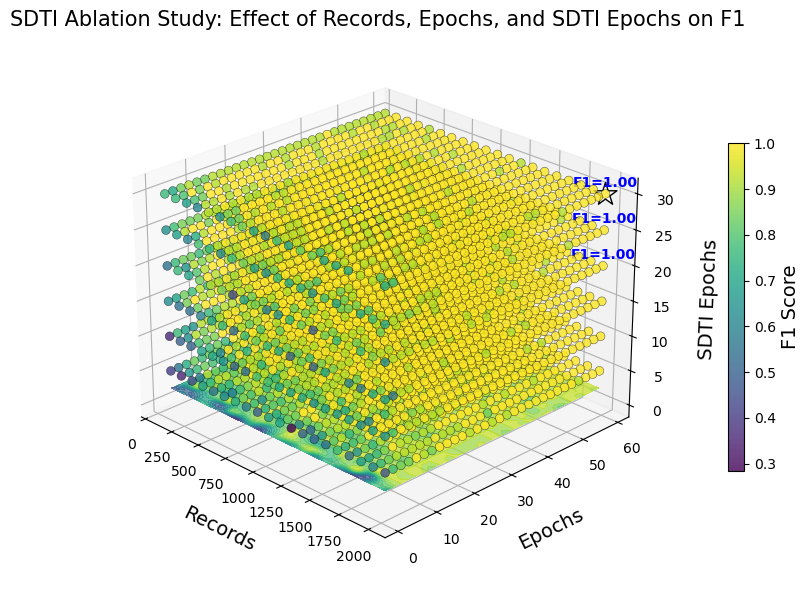

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

# Assuming results is a pandas DataFrame
x = results['records']
y = results['epochs']
z = results['sdti_epochs']
f1 = results['f1']

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

fontsize = 14

# --- Main 3D scatter ---
sc = ax.scatter(
    x, y, z,
    c=f1,
    cmap='viridis',
    alpha=0.8,
    s=40,
    edgecolors='k',
    linewidths=0.3
)

# --- Create smoothed grid for contour projection ---
from scipy.interpolate import griddata

# Define grid on (x, y)
xi = np.linspace(min(x), max(x), 100)
yi = np.linspace(min(y), max(y), 100)
Xi, Yi = np.meshgrid(xi, yi)

# Interpolate F1 values onto this grid
Zi = griddata((x, y), f1, (Xi, Yi), method='cubic')

# --- Add contour projection on z=constant plane (for readability) ---
contours = ax.contourf(
    Xi, Yi, Zi,
    zdir='z', offset=min(z) - 0.1*(max(z)-min(z)),
    cmap='viridis',
    alpha=0.7,
    levels=15
)

# --- Highlight best performing configuration ---
best_idx = np.argmax(f1)
ax.scatter(
    x.iloc[best_idx], y.iloc[best_idx], z.iloc[best_idx],
    color='white', edgecolor='black',
    s=300, marker='*', label='Best configuration', zorder=10, depthshade = False
)

# --- Annotate representative points ---
top3 = results.nlargest(3, 'f1')
for i, row in top3.iterrows():
    ax.text(
        row['records'], row['epochs'], row['sdti_epochs']+0.02*(max(z)-min(z)),
        f"F1={row['f1']:.2f}",
        fontsize=10, color='blue', ha='center', va='bottom', weight='bold'
    )

# --- Axes and labels ---
ax.set_xlabel('Records', fontsize=fontsize, labelpad=10)
ax.set_ylabel('Epochs', fontsize=fontsize, labelpad=10)
ax.set_zlabel('SDTI Epochs', fontsize=fontsize, labelpad=10)

ax.view_init(elev=25, azim=-45)

# --- Colorbar ---
cbar = plt.colorbar(sc, ax=ax, shrink=0.6, pad=0.1)
cbar.set_label('F1 Score', fontsize=fontsize)

# --- Title ---
plt.title('SDTI Ablation Study: Effect of Records, Epochs, and SDTI Epochs on F1', fontsize=fontsize+1)

# --- Save figure ---
plt.tight_layout()
plt.savefig('ablation_results_enhanced.jpg', dpi=300, bbox_inches='tight')
plt.show()


In [7]:
over500 = results[results['records']>=500]
under500 = results[results['records']<500]

print('over500')
print(over500.describe())
print('under500')
print(under500.describe())


over10 = results[results['epochs']>=10]
under10 = results[results['epochs']<10]

print('over10')
print(over10.describe())
print('under10')
print(under10.describe())

sdti30 = results[results['sdti_epochs']==30]
sdti5 = results[results['sdti_epochs']==5]


print('over30')
print(sdti30.describe())
print('under5')
print(sdti5.describe())

over500
           records       epochs  sdti_epochs           f1       memory  \
count  2880.000000  2880.000000  2880.000000  2880.000000  2880.000000   
mean   1250.000000    30.000000    17.500000     0.970524     4.157647   
std     461.057274    17.313889     8.540609     0.073312     1.526407   
min     500.000000     1.000000     5.000000     0.284300     1.673737   
25%     875.000000    15.000000    10.000000     1.000000     2.915488   
50%    1250.000000    30.000000    17.500000     1.000000     4.157312   
75%    1625.000000    45.000000    25.000000     1.000000     5.399207   
max    2000.000000    59.000000    30.000000     1.000000     6.641174   

              data          ttc  
count  2880.000000  2880.000000  
mean      6.615224     1.181696  
std       0.000000     0.857765  
min       6.615224     0.013349  
25%       6.615224     0.498764  
50%       6.615224     1.002376  
75%       6.615224     1.710387  
max       6.615224     4.344491  
under500
          

In [8]:
final_test = results[(results['records'] >= 500) & (results['epochs'] >= 10) & (results['sdti_epochs']==30)]
final_test.describe()

# final_test = results[(results['records'] < 500) & (results['epochs'] < 10) & (results['sdti_epochs']==5)]
# final_test.describe()

,records,epochs,sdti_epochs,f1,memory,data,ttc
count,400.000000,400.000000,400.0,400.000000,400.000000,400.000000,400.000000
mean,1250.000000,35.000000,30.0,0.990004,4.158096,6.615224,1.626867
std,461.554527,14.440267,0.0,0.026182,1.528101,0.000000,0.921982
min,500.000000,11.000000,30.0,0.921600,1.675019,6.615224,0.212151
25%,875.000000,23.000000,30.0,1.000000,2.916558,6.615224,0.890976
50%,1250.000000,35.000000,30.0,1.000000,4.158096,6.615224,1.431022
75%,1625.000000,47.000000,30.0,1.000000,5.399635,6.615224,2.201457
max,2000.000000,59.000000,30.0,1.000000,6.641174,6.615224,4.344491
